# Sandbox: synthetic spectrum fitting with kinextract

A clean, self-contained playground for making a synthetic galaxy spectrum with a known truth (V, sigma, h3, h4), fitting it with the current kinextract code, and plotting the recovered-vs-true bias yourself.

Everything you'd want to change is in the **Parameters** cell below. Re-run from there down after changing anything.

Always imports from kinextract fresh (via sys.path, not a pinned/installed copy), so this reflects whatever is currently in src/kinextract/ -- no need to reinstall the package after editing it.

In [1]:
import sys, os

# Assumes this notebook stays in examples/notebooks/ (repo layout: <repo>/src, <repo>/examples/notebooks/).
# Edit this path directly if you move the notebook elsewhere.
SRC_DIR = "/Users/waterstk/Documents/Gultekin_Astrophysics/kinextract/src"
sys.path.insert(0, SRC_DIR)

import warnings
import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, gauss_hermite_model,
    fit_losvd, bootstrap_losvd, compute_losvd_moments,
)

import kinextract
print("kinextract version:", kinextract.__version__)
print("loaded from:", kinextract.__file__)

kinextract version: 0.2.0
loaded from: /Users/waterstk/Documents/Gultekin_Astrophysics/kinextract/src/kinextract/__init__.py


## Templates

Real 33-star MUSE Library of Stellar Spectra by default (`USE_REAL_TEMPLATES = True`), with a fixed representative population mixture -- matching every other synthetic test built this session, so results here are directly comparable. Flip to `False` for a single toy template (a few Gaussian absorption lines) if you want the simplest possible case with no multi-template weight-fitting at all.

In [2]:
USE_REAL_TEMPLATES = True  # False -> single toy template, no template-mixture degeneracy at all
MUSE_TEMPLATE_DIR = "/Users/waterstk/Documents/Gultekin_Astrophysics/sco_framework_updated/sco_workdir_example/analysis/muse_templates/old"
MIXTURE_SEED = 20000  # fixed Dirichlet mixture, same one used throughout this session's tests

WAVELENGTH = 4750.0 + np.arange(3681) * 1.25  # MUSE-like grid, 4750-9350 A at 1.25 A/pix
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0  # CaII triplet fit window

def _toy_template(wavelength):
    t = np.ones_like(wavelength)
    for cen, depth in zip([8498.02, 8542.09, 8662.14], [0.55, 0.70, 0.65]):
        t -= depth * np.exp(-0.5 * ((wavelength - cen) / 5.0) ** 2)
    return t

if USE_REAL_TEMPLATES:
    with open(os.path.join(MUSE_TEMPLATE_DIR, "Tlist")) as f:
        names = [line.strip() for line in f if line.strip()]
    templates = []
    for name in names:
        d = np.loadtxt(os.path.join(MUSE_TEMPLATE_DIR, name))
        templates.append(np.interp(WAVELENGTH, d[:, 0], d[:, 1]))
    rng_mix = np.random.default_rng(MIXTURE_SEED)
    true_weights = rng_mix.dirichlet(np.ones(len(templates)))
    print(f"loaded {len(templates)} real MUSE templates, fixed mixture (seed={MIXTURE_SEED})")
else:
    templates = [_toy_template(WAVELENGTH)]
    true_weights = np.array([1.0])
    print("using a single toy template -- no multi-template weight degeneracy")

mask = (WAVELENGTH >= WAVEFITMIN) & (WAVELENGTH <= WAVEFITMAX)
wave_fit = WAVELENGTH[mask]

loaded 33 real MUSE templates, fixed mixture (seed=20000)


## Parameters

Everything here is a dial. `LAM=0.0` is unregularized (the ablation-ladder/coverage-test finding: this often does *better* at low sigma, worse at high sigma). `H4_TRUE != 0.0` gives a genuine non-Gaussian wing -- the case the shipped bias correction was never calibrated for (see `bias_correction.py`'s own docstring: calibrated at true h4=0 only).

In [3]:
# --- true LOSVD ---
V_TRUE = 0.0        # km/s
SIGMA_TRUE = 150.0  # km/s
H3_TRUE = 0.0       # skewness; 0 = symmetric
H4_TRUE = 0.0       # kurtosis excess; try 0.15 for a genuine high-velocity wing

# --- observing conditions ---
SNR = 60.0          # signal-to-noise per pixel
SEED = 42           # noise draw; change for a different realization

# --- fit configuration ---
LAM = 1.0           # curvature-penalty regularization strength (shipped default: 2.0; try 0.0)
WING_LAM = 0.0      # wing-amplitude penalty (off by default; see FitConfig.describe("wing_lam"))
NSIG = 7.0          # velocity grid half-width in units of SIGMA_TRUE (validated convention)

# --- bootstrap / bias correction ---
N_BOOT = 30
APPLY_BIAS_CORRECTION = True  # the Pinkney-style correction -- see caveat above re: H4_TRUE != 0

print(f"true: V={V_TRUE}, sigma={SIGMA_TRUE}, h3={H3_TRUE}, h4={H4_TRUE}   S/N={SNR}   lam={LAM}")

true: V=0.0, sigma=150.0, h3=0.0, h4=0.0   S/N=60.0   lam=1.0


## Build the synthetic spectrum

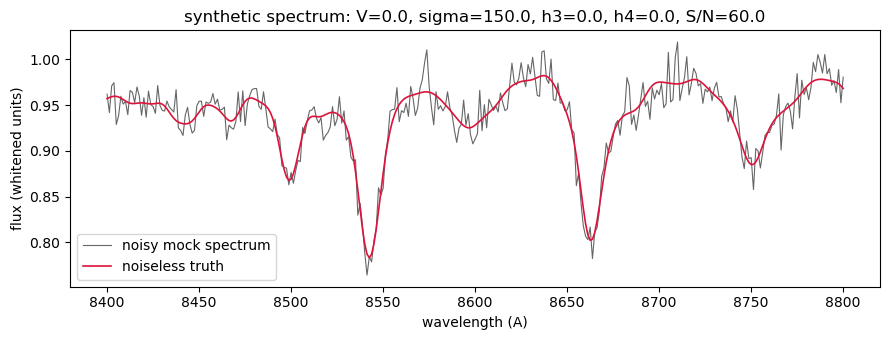

In [4]:
cfg = FitConfig(vmin=V_TRUE - NSIG * SIGMA_TRUE, vmax=V_TRUE + NSIG * SIGMA_TRUE, lam=LAM, wing_lam=WING_LAM)
v_grid = cfg.build_velocity_grid()

b_truth = np.maximum(gauss_hermite_model(v_grid, 1.0, V_TRUE, SIGMA_TRUE, H3_TRUE, H4_TRUE), 0.0)
b_truth /= b_truth.sum()

A_stack = build_template_stack(wave_fit, WAVELENGTH, templates, v_grid)
galaxy_noiseless = sum(true_weights[k] * (A_stack[k] @ b_truth) for k in range(len(templates)))
noise_level = np.median(galaxy_noiseless) / SNR

rng = np.random.default_rng(SEED)
galaxy = galaxy_noiseless + rng.normal(0.0, noise_level, len(wave_fit))
errors = np.full(len(wave_fit), noise_level)

A_stack_w = A_stack / errors[None, :, None]
y_w = galaxy / errors

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(wave_fit, galaxy, lw=0.8, color="0.4", label="noisy mock spectrum")
ax.plot(wave_fit, galaxy_noiseless, lw=1.2, color="crimson", label="noiseless truth")
ax.set_xlabel("wavelength (A)"); ax.set_ylabel("flux (whitened units)")
ax.legend(); ax.set_title(f"synthetic spectrum: V={V_TRUE}, sigma={SIGMA_TRUE}, h3={H3_TRUE}, h4={H4_TRUE}, S/N={SNR}")
plt.tight_layout(); plt.show()

## Fit it, and compare against the known truth

`bootstrap_losvd` returns both the raw (uncorrected) and bias-corrected point estimates plus uncertainty -- see its own docstring for exactly what each key means. The "true" numbers below are the numerically-integrated moments of the actual Gauss-Hermite truth (not just `V_TRUE`/`SIGMA_TRUE` directly -- these only equal the true moments exactly when h3=h4=0, see `gh_moments.py`'s docstring).

In [5]:
warnings.filterwarnings("ignore")  # FitConfig/wing_lam warnings -- re-enable if you want to see them

# numerically-integrated true moments (exact only for h3=h4=0; see gh_moments.py docstring)
vv = np.linspace(V_TRUE - 15 * SIGMA_TRUE, V_TRUE + 15 * SIGMA_TRUE, 200_001)
bb = np.maximum(gauss_hermite_model(vv, 1.0, V_TRUE, SIGMA_TRUE, H3_TRUE, H4_TRUE), 0.0)
tot = np.trapezoid(bb, vv)
true_v = float(np.trapezoid(bb * vv, vv) / tot)
true_s = float(np.sqrt(np.trapezoid(bb * (vv - true_v) ** 2, vv) / tot))

boot = bootstrap_losvd(A_stack_w, y_w, cfg, n_boot=N_BOOT, seed=SEED + 1,
                        apply_bias_correction=APPLY_BIAS_CORRECTION)

raw = boot["point0"]
corrected = boot["point0_corrected"]


print(f"{'':>12} {'true':>10} {'raw':>10} {'raw bias':>10}   {'corrected':>10} {'corr bias':>10}")
print(f"{'V':>12} {true_v:10.2f} {raw['vherm']:10.2f} {raw['vherm']-true_v:+10.2f}   "
      f"{corrected['vherm']:10.2f} {corrected['vherm']-true_v:+10.2f}")
print(f"{'sigma':>12} {true_s:10.2f} {raw['sherm']:10.2f} {raw['sherm']-true_s:+10.2f}   "
      f"{corrected['sherm']:10.2f} {corrected['sherm']-true_s:+10.2f}   (std={boot['sherm_std_corrected']:.2f})")
print(f"{'h3':>12} {H3_TRUE:10.3f} {raw['h3']:10.3f} {raw['h3']-H3_TRUE:+10.3f}   "
      f"{corrected['h3']:10.3f} {corrected['h3']-H3_TRUE:+10.3f}")
print(f"{'h4':>12} {H4_TRUE:10.3f} {raw['h4']:10.3f} {raw['h4']-H4_TRUE:+10.3f}   "
      f"{corrected['h4']:10.3f} {corrected['h4']-H4_TRUE:+10.3f}   (std={boot['h4_std_corrected']:.3f})")
print(f"\nestimated whitened S/N: {boot['snr_estimated']:.1f}")

                   true        raw   raw bias    corrected  corr bias
           V      -0.00      -4.24      -4.24        -4.24      -4.24
       sigma     150.00     181.68     +31.68       150.83      +0.83   (std=47.68)
          h3      0.000     -0.015     -0.015       -0.015     -0.015
          h4      0.000      0.017     +0.017       -0.025     -0.025   (std=0.078)

estimated whitened S/N: 60.0


## Plot: true vs. recovered LOSVD, with the bootstrap band

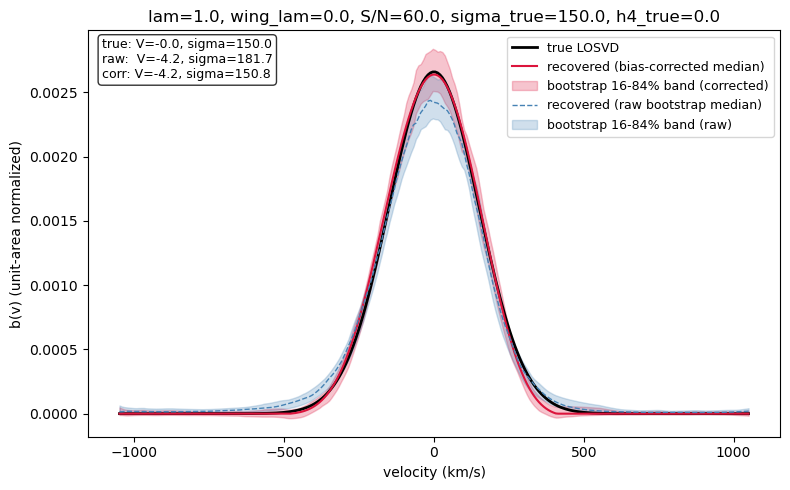

In [6]:
boot_median_corr = boot["b_median_corrected"] / np.trapezoid(boot["b_median_corrected"], v_grid)  # renormalize to unit area

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(v_grid, b_truth/(np.trapezoid(b_truth, v_grid)), color="k", lw=2, label="true LOSVD")
ax.plot(v_grid, boot_median_corr, color="crimson", lw=1.5, label="recovered (bias-corrected median)")
ax.fill_between(v_grid, boot["b_p16_corrected"], boot["b_p84_corrected"], color="crimson", alpha=0.25,
                 label="bootstrap 16-84% band (corrected)")
ax.plot(v_grid, np.median(boot["b_boot"], axis=0), color="steelblue", lw=1.0, ls="--",
        label="recovered (raw bootstrap median)")
ax.fill_between(v_grid, np.percentile(boot["b_boot"], 16, axis=0), np.percentile(boot["b_boot"], 84, axis=0), 
                color="steelblue", alpha=0.25, label="bootstrap 16-84% band (raw)")

# annotate true vs recovered moments
textstr = "\n".join((
    f"true: V={true_v:.1f}, sigma={true_s:.1f}",
    f"raw:  V={raw['vherm']:.1f}, sigma={raw['sherm']:.1f}",
    f"corr: V={corrected['vherm']:.1f}, sigma={corrected['sherm']:.1f}",
))

ax.text(0.02, 0.98, textstr, transform=ax.transAxes, fontsize=9, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel("velocity (km/s)"); ax.set_ylabel("b(v) (unit-area normalized)")
ax.legend(fontsize=9)
ax.set_title(f"lam={LAM}, wing_lam={WING_LAM}, S/N={SNR}, sigma_true={SIGMA_TRUE}, h4_true={H4_TRUE}")
plt.tight_layout(); plt.show()

## Sweep: bias vs. sigma, fixed lam vs. adaptive lam, all four moments

Uses `bias_sweep_fixed_vs_adaptive.py` (same directory) rather than an inline loop, for two reasons: (1) it computes **both** a fixed-`lam` case and an adaptive-`lam` case (`select_lambda_aic_local`) on the *same* noise draw per replicate, across **all four** moments (V, sigma, h3, h4) -- not just sigma/h4; (2) it parallelizes across every (sigma, rep) combination with `ProcessPoolExecutor`, which only works reliably from a real importable module, not a function defined in a notebook cell (macOS's `spawn` start method can't pickle a notebook-local function for the worker processes). The original inline version of this sweep (fixed-lam, sigma/h4 only) took ~47.5 minutes sequentially; parallelized across this machine's cores, the fuller version (both cases, all four moments) runs in a fraction of that.

Set `USE_CACHED_RESULTS = True` to load an already-finished run (`bias_sweep_fixed_vs_adaptive_results.txt`) instantly rather than recomputing -- flip to `False` (or change any parameter below) to force a fresh run.

In [ ]:
import bias_sweep_fixed_vs_adaptive as bsfa

SWEEP_SIGMA_GRID = [30, 50, 80, 140, 220, 300]
SWEEP_N_REPS = 15
SWEEP_LAM_FIXED = 2.0
USE_CACHED_RESULTS = True  # True: load the already-finished run instantly; False: recompute now (parallelized)

RESULTS_PATH = "bias_sweep_fixed_vs_adaptive_results.txt"

def _load_results(path):
    rows = []
    with open(path) as f:
        header = f.readline()
        for line in f:
            parts = line.split()
            rows.append(dict(
                sigma=float(parts[0]), case=parts[1],
                v_mean=float(parts[2]), v_std=float(parts[3]),
                sig_mean=float(parts[4]), sig_std=float(parts[5]),
                h3_mean=float(parts[6]), h3_std=float(parts[7]),
                h4_mean=float(parts[8]), h4_std=float(parts[9]),
                mean_lam=float(parts[10]),
            ))
    return rows

if USE_CACHED_RESULTS and os.path.exists(RESULTS_PATH):
    rows = _load_results(RESULTS_PATH)
    print(f"loaded {len(rows)} cached rows from {RESULTS_PATH} -- set USE_CACHED_RESULTS=False to recompute")
else:
    rows = bsfa.run(sigma_grid=SWEEP_SIGMA_GRID, n_reps=SWEEP_N_REPS, lam_fixed=SWEEP_LAM_FIXED,
                     h4_true=H4_TRUE, h3_true=H3_TRUE, v_true=V_TRUE)
    bsfa.save_rows(rows, RESULTS_PATH)

by_case = {"fixed": [r for r in rows if r["case"] == "fixed"],
           "adaptive": [r for r in rows if r["case"] == "adaptive"]}
colors = {"fixed": "steelblue", "adaptive": "crimson"}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
panels = [("v_mean", "v_std", "V bias (km/s)", axes[0, 0]),
          ("sig_mean", "sig_std", "sigma bias (km/s)", axes[0, 1]),
          ("h3_mean", "h3_std", "h3 bias", axes[1, 0]),
          ("h4_mean", "h4_std", "h4 bias", axes[1, 1])]
for mean_key, std_key, ylabel, ax in panels:
    for case in ("fixed", "adaptive"):
        r = by_case[case]
        vals = [x["sigma"] for x in r]
        means = [x[mean_key] for x in r]
        stds = [x[std_key] for x in r]
        ax.errorbar(vals, means, yerr=stds, marker="o", label=case, color=colors[case])
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xlabel("sigma_true (km/s)"); ax.set_ylabel(ylabel); ax.legend(fontsize=9)

mean_lams = {r["sigma"]: r["mean_lam"] for r in by_case["adaptive"]}
plt.suptitle(f"fixed lam={SWEEP_LAM_FIXED} vs. adaptive lam (select_lambda_aic_local)  "
             f"[h3_true={H3_TRUE}, h4_true={H4_TRUE}, S/N={SNR}, N_REPS={SWEEP_N_REPS}]\n"
             f"adaptive mean_lam by sigma: " + ", ".join(f"{s:.0f}:{l:.1f}" for s, l in mean_lams.items()),
             fontsize=10)
plt.tight_layout(); plt.show()